# 03 — Treatment Analysis (thesis Section 4.2.1, Table 4.5, Figs 4.7–4.12)

One-sided Mann–Whitney U tests: are wildfires that had a prescribed burn within R km in the previous T months
smaller than wildfires that did not? (`alternative="less"`; CLES is the common-language effect size.)

**Input:** `data/processed/prescribed_treatment_data_new.csv`, the 2,041-row version *before* the final cleaning
(it still has fires with missing county and has no `max_wind`).

**Outputs:** `figures/bp_3m.pdf`, `bp_6m.pdf`, `bp_9m.pdf`, `bp_12m.pdf`, `bp_24m.pdf`, `bp_36m.pdf` and the printed U-test tables.

**Notes for future work**
* `log_acres` is computed as `log(log_incident_acres_burned)`, a **double log**. Mann–Whitney is rank-based,
  so this barely changes the results (it only reorders fires of 1–2.7 acres), but new analyses should use
  `log_incident_acres_burned` directly.
* The U values printed here differ slightly from thesis Table 4.5 (e.g. 116462.5 vs 116580.5). The 2024 outputs of this
  notebook differ in the same way, so the thesis table was made from a slightly earlier version of the data. The p-values and
  conclusions are the same.
* These are many tests without multiple-comparison correction, and they ignore confounding by climate and location;
  see `docs/FUTURE_WORK.md`.

In [1]:
import pandas as pd
from functions import *

In [2]:
df = pd.read_csv("data/processed/prescribed_treatment_data_new.csv", index_col=0)

In [3]:
df["log_acres"] = np.log(df['log_incident_acres_burned'].replace(0, np.nan)).replace(np.nan, 0)

In [4]:
df.columns

Index(['ex_date', 'incident_name', 'incident_county', 'incident_acres_burned',
       'incident_longitude', 'incident_latitude', 'incident_type', 'tavg',
       'tmax', 'tmin', 'pcp', 'cdd', 'hdd', 'pdsi', 'phdi', 'pmdi', 'zndx',
       'prescribed_3_months_in_5km', 'prescribed_3_months_size_5km',
       'prescribed_3_months_in_10km', 'prescribed_3_months_size_10km',
       'prescribed_3_months_in_25km', 'prescribed_3_months_size_25km',
       'prescribed_3_months_in_50km', 'prescribed_3_months_size_50km',
       'prescribed_3_months_in_100km', 'prescribed_3_months_size_100km',
       'prescribed_6_months_in_5km', 'prescribed_6_months_size_5km',
       'prescribed_6_months_in_10km', 'prescribed_6_months_size_10km',
       'prescribed_6_months_in_25km', 'prescribed_6_months_size_25km',
       'prescribed_6_months_in_50km', 'prescribed_6_months_size_50km',
       'prescribed_6_months_in_100km', 'prescribed_6_months_size_100km',
       'prescribed_9_months_in_5km', 'prescribed_9_months_si

In [5]:
import pingouin as pg

In [6]:
expected, observed, stats = pg.chi2_independence(df, x='prescribed_3_months_in_25km',
                                                 y='incident_county')

/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/pingouin/contingency.py:150: UserWarning: Low count on observed frequencies.
  warnings.warn("Low count on {} frequencies.".format(name))
/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/pingouin/contingency.py:150: UserWarning: Low count on expected frequencies.
  warnings.warn("Low count on {} frequencies.".format(name))
/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/scipy/stats/_stats_py.py:8073: RuntimeWarning: divide by zero encountered in power
  terms = f_obs * ((f_obs / f_exp)**lambda_ - 1)
/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/scipy/stats/_stats_py.py:8073: RuntimeWarning: invalid value encountered in multiply
  terms = f_obs * ((f_obs / f_exp)**lambda_ - 1)
/opt/anaconda3/envs/thesis/lib/python3.11/site-packages/scipy/stats/_stats_py.py:8070: RuntimeWarning: divide by zero encountered in divide
  terms = 2.0 * special.xlogy(f_exp, f_exp / f_obs)


In [7]:
stats

,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.000000,293.557259,95.0,3.914852e-22,0.379249,1.0
1,cressie-read,0.666667,294.892781,95.0,2.474519e-22,0.380111,1.0
2,log-likelihood,0.000000,318.210019,95.0,7.128242e-26,0.394853,1.0
3,freeman-tukey,-0.500000,NaN,95.0,NaN,NaN,NaN
4,mod-log-likelihood,-1.000000,inf,95.0,0.000000e+00,inf,NaN
5,neyman,-2.000000,NaN,95.0,NaN,NaN,NaN


In [8]:
observed

incident_county,Alameda,Alpine,Amador,"Amador, Calaveras","Amador, El Dorado",Butte,"Butte, Plumas, Shasta, Lassen, Tehama",Calaveras,Colusa,"Colusa, Lake, Mendocino",...,State of Oregon,Sutter,Tehama,"Tehama, Glenn",Trinity,Tulare,Tuolumne,Ventura,Yolo,Yuba
prescribed_3_months_in_25km,,,,,,,,,,,,,,,,,,,,,
False,27,4,7,0,1,43,1,18,4,0,...,1,4,47,1,18,32,14,24,10,20
True,6,0,7,1,0,35,0,11,3,1,...,0,0,15,0,3,17,16,1,3,8


In [9]:
expected

incident_county,Alameda,Alpine,Amador,"Amador, Calaveras","Amador, El Dorado",Butte,"Butte, Plumas, Shasta, Lassen, Tehama",Calaveras,Colusa,"Colusa, Lake, Mendocino",...,State of Oregon,Sutter,Tehama,"Tehama, Glenn",Trinity,Tulare,Tuolumne,Ventura,Yolo,Yuba
prescribed_3_months_in_25km,,,,,,,,,,,,,,,,,,,,,
False,23.573738,2.857423,10.00098,0.714356,0.714356,55.719745,0.714356,20.716316,5.00049,0.714356,...,0.714356,2.857423,44.290054,0.714356,15.00147,35.00343,21.430671,17.858893,9.286624,20.00196
True,9.426262,1.142577,3.99902,0.285644,0.285644,22.280255,0.285644,8.283684,1.99951,0.285644,...,0.285644,1.142577,17.709946,0.285644,5.99853,13.99657,8.569329,7.141107,3.713376,7.99804


# 3 Months

In [10]:
target = "log_acres"
predictors = ["prescribed_3_months_in_10km", "prescribed_3_months_in_25km", "prescribed_3_months_in_50km", "prescribed_3_months_in_100km"]
bp = build_boxplots(df, target, predictors= predictors)
bp.savefig("figures/bp_3m.pdf")

<Figure size 1200x600 with 4 Axes>

In [11]:
mwu, t = run_stats(df, "log_acres", predictors, alt="less")
display(mwu.round(3))

,,U-val,alternative,p-val,RBC,CLES
prescribed_3_months_in_10km,MWU,116462.5,less,0.002,0.142,0.571
prescribed_3_months_in_25km,MWU,398860.5,less,0.015,0.062,0.531
prescribed_3_months_in_50km,MWU,470156.5,less,0.000,0.085,0.542
prescribed_3_months_in_100km,MWU,324331.0,less,0.044,0.054,0.527


# 6 months

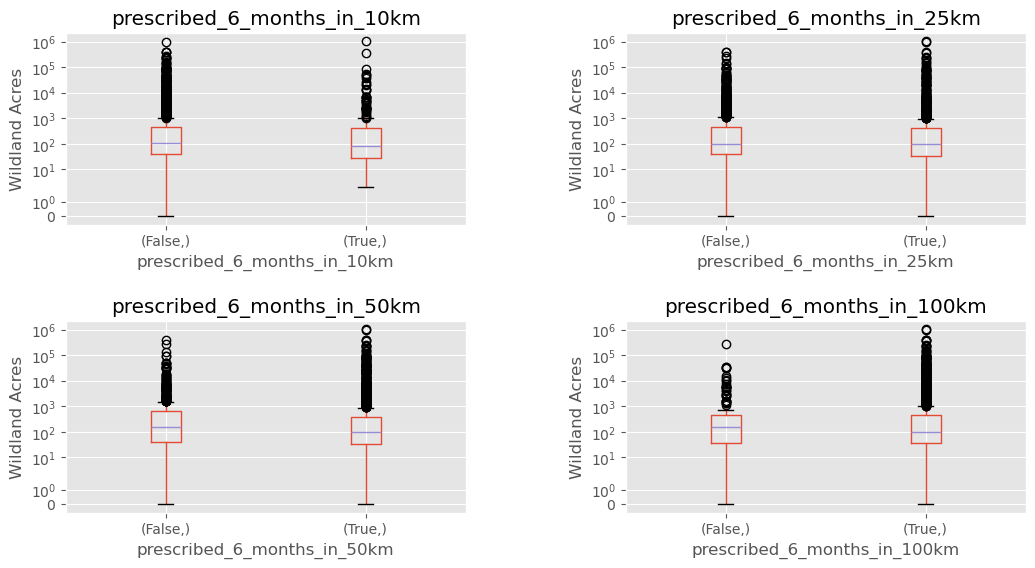

In [12]:
target = "log_acres"
predictors = ["prescribed_6_months_in_10km","prescribed_6_months_in_25km", "prescribed_6_months_in_50km", "prescribed_6_months_in_100km"]
bp = build_boxplots(df, target, predictors= predictors)
bp.savefig("figures/bp_6m.pdf")

In [13]:
mwu, t = run_stats(df, "log_acres", predictors, alt="less")
display(mwu.round(3))

,,U-val,alternative,p-val,RBC,CLES
prescribed_6_months_in_10km,MWU,197126.0,less,0.011,0.091,0.546
prescribed_6_months_in_25km,MWU,505491.5,less,0.343,0.010,0.505
prescribed_6_months_in_50km,MWU,369548.0,less,0.002,0.085,0.542
prescribed_6_months_in_100km,MWU,134611.5,less,0.081,0.068,0.534


# 9 months

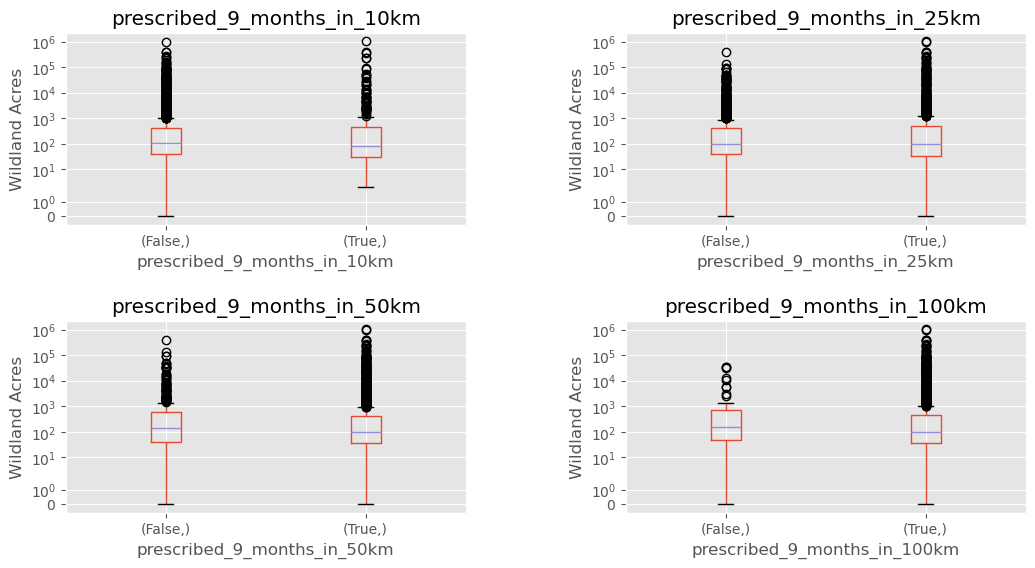

In [14]:
target = "log_acres"
predictors = ["prescribed_9_months_in_10km","prescribed_9_months_in_25km","prescribed_9_months_in_50km", "prescribed_9_months_in_100km"]
bp = build_boxplots(df, target, predictors= predictors)
bp.savefig("figures/bp_9m.pdf")

In [15]:
mwu, t = run_stats(df, "log_acres", predictors,alt="less")
display(mwu.round(3))

,,U-val,alternative,p-val,RBC,CLES
prescribed_9_months_in_10km,MWU,253232.5,less,0.016,0.076,0.538
prescribed_9_months_in_25km,MWU,519676.0,less,0.473,0.002,0.501
prescribed_9_months_in_50km,MWU,284184.5,less,0.004,0.086,0.543
prescribed_9_months_in_100km,MWU,41149.0,less,0.030,0.157,0.578


# 12 months

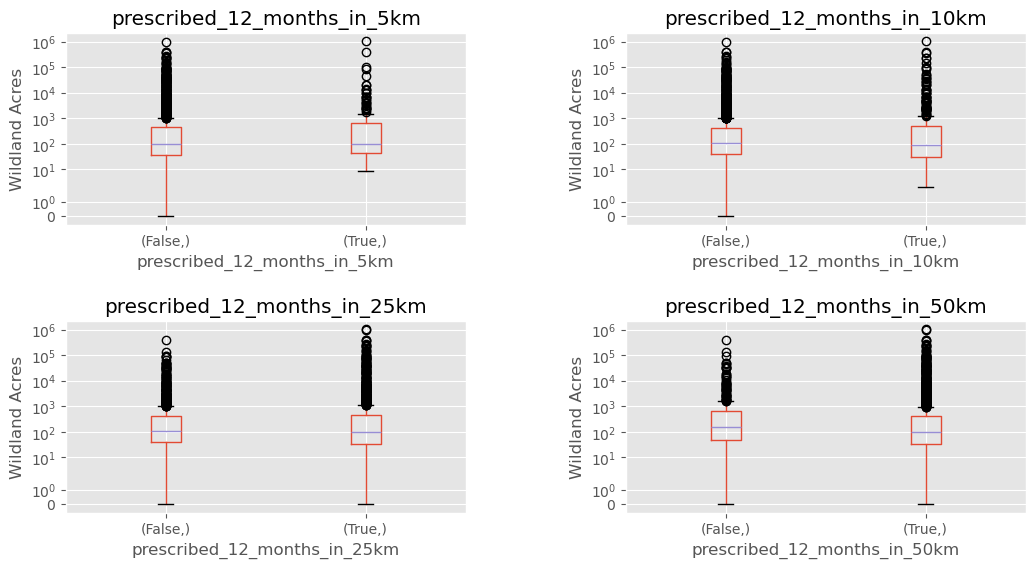

In [16]:
target = "log_acres"
predictors = ["prescribed_12_months_in_5km", "prescribed_12_months_in_10km","prescribed_12_months_in_25km", "prescribed_12_months_in_50km"]
bp = build_boxplots(df, target, predictors= predictors)
bp.savefig("figures/bp_12m.pdf")

In [17]:
mwu, t = run_stats(df, "log_acres", predictors,alt="less")
display(mwu.round(3))

,,U-val,alternative,p-val,RBC,CLES
prescribed_12_months_in_5km,MWU,136871.0,less,0.618,-0.015,0.492
prescribed_12_months_in_10km,MWU,298599.0,less,0.039,0.058,0.529
prescribed_12_months_in_25km,MWU,500004.5,less,0.194,0.022,0.511
prescribed_12_months_in_50km,MWU,214617.0,less,0.000,0.132,0.566


# 24 months

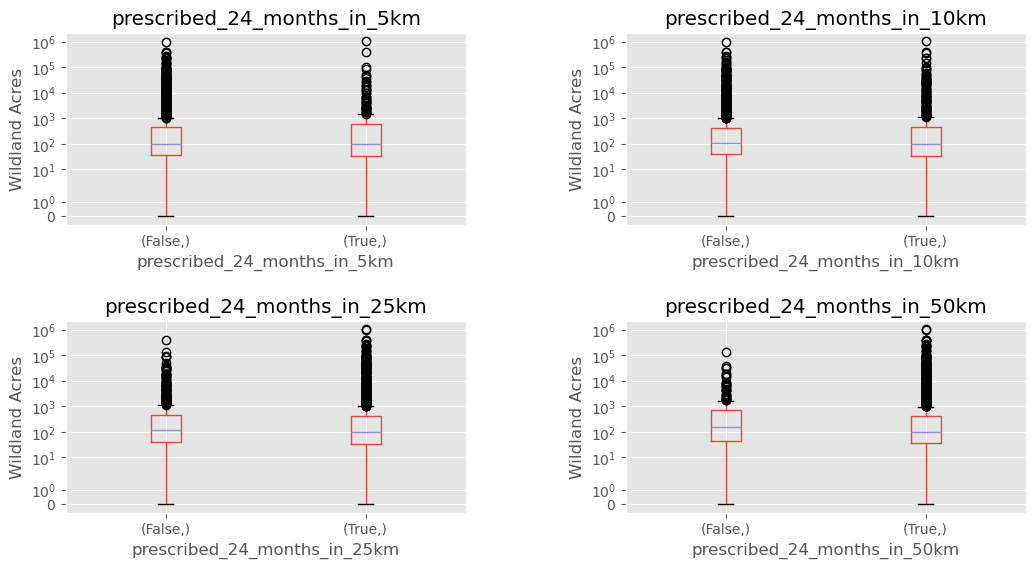

In [18]:
target = "log_acres"
predictors = ["prescribed_24_months_in_5km", "prescribed_24_months_in_10km","prescribed_24_months_in_25km", "prescribed_24_months_in_50km"]
bp = build_boxplots(df, target, predictors= predictors)
bp.savefig("figures/bp_24m.pdf")

In [19]:
mwu, t = run_stats(df, "log_acres", predictors, alt="less")
display(mwu.round(3))

,,U-val,alternative,p-val,RBC,CLES
prescribed_24_months_in_5km,MWU,191320.0,less,0.415,0.009,0.505
prescribed_24_months_in_10km,MWU,385398.0,less,0.049,0.048,0.524
prescribed_24_months_in_25km,MWU,434569.5,less,0.047,0.046,0.523
prescribed_24_months_in_50km,MWU,133398.0,less,0.012,0.108,0.554


# 36 Months

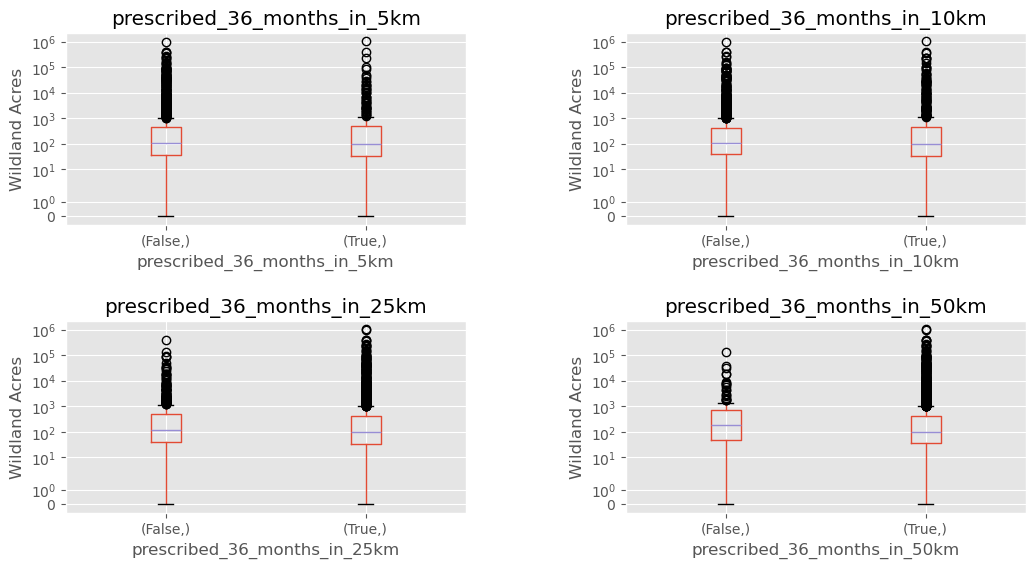

In [20]:
target = "log_acres"
predictors = ["prescribed_36_months_in_5km", "prescribed_36_months_in_10km","prescribed_36_months_in_25km","prescribed_36_months_in_50km"]
bp = build_boxplots(df, target, predictors= predictors)
bp.savefig("figures/bp_36m.pdf")

In [21]:
mwu, t = run_stats(df, "log_acres", predictors,alt="less")
display(mwu.round(3))

,,U-val,alternative,p-val,RBC,CLES
prescribed_36_months_in_5km,MWU,213278.0,less,0.274,0.024,0.512
prescribed_36_months_in_10km,MWU,434681.5,less,0.085,0.038,0.519
prescribed_36_months_in_25km,MWU,385320.5,less,0.017,0.061,0.531
prescribed_36_months_in_50km,MWU,90581.5,less,0.007,0.140,0.570
